Authors:
- Cezary Suchorski 160310
- Bartosz Tarnachowicz 160304

Code repo: https://github.com/csuchorski/evolutionary_computation

# Speeding up local search with a list of improving moves

**Evolutionary Computation · Laboratory 5**

We select exactly half of the nodes and connect them into one closed tour. A
local search improves a solution by small changes called **moves**. The steepest
version checks every possible move in every iteration. This is accurate, but it
is also the main cost of the method.

This report shows how to store improving moves together with their change in
objective — the **delta** — and reuse those values in later iterations. The
result is the **list of improving moves (LM)**.

We focus the comparison on four methods:

- full steepest local search (the baseline),
- steepest local search with the LM,
- steepest local search with candidate moves,
- LM restricted to candidate moves.

A plain random solution is included as a reference point. The remaining
heuristics and local-search variants from earlier experiments are included in
the results for context, but the discussion focuses on the four methods above.

| | |
|---|---|
| Instances | TSPA, TSPB — 200 nodes each |
| Selected nodes | k = 100 |
| Runs | 200 per method and instance |
| Starting solutions | random tours; the LM methods and the baseline use the same 200 tours |

## 1. Problem

Each instance contains **n = 200** points. Point *i* has coordinates
(*x<sub>i</sub>*, *y<sub>i</sub>*) and an integer cost *c<sub>i</sub>*. We must
select exactly **k = ceil(n/2) = 100** nodes and build one closed tour that
visits every selected node exactly once. We minimise

<p align="center">
F(T) = &Sigma;<sub>i=0</sub><sup>k&minus;1</sup> [ c<sub>t<sub>i</sub></sub> + dist(t<sub>i</sub>, t<sub>i+1</sub>) ],&nbsp;&nbsp;&nbsp; t<sub>k</sub> = t<sub>0</sub>,
</p>

where dist(i, j) is the Euclidean distance rounded to the nearest integer. The
objective is therefore the sum of the costs of the selected nodes plus the
length of the closed tour.

## 2. Data

Each instance has 200 points described by `x`, `y` and `cost`. Distances are
Euclidean, rounded to the nearest integer, and symmetric. The distance matrix is
computed once, immediately after reading an instance.

The candidate methods also build candidate lists. These lists are rebuilt for
every run, so their construction is included in the measured running time.

## 3. Moves

A move is a small change of the current tour. We use two types.

**Node exchange.** Replace one selected node `u` by one unselected node `v`.
The rest of the tour order stays the same; the two neighbours of `u` are
reconnected to `v`.

**Edge exchange (2-opt).** Remove two tour edges `(a, b)` and `(c, d)`, add
`(a, c)` and `(b, d)`, and reverse the part of the tour between the removed
edges. The selected set does not change.

Every move changes only a few edges, so its effect on the objective can be
computed in constant time. We never rebuild the whole tour to evaluate a move.

## 4. Move deltas

The **delta** of a move is its new objective minus the old objective. A
negative delta means the move improves the solution.

For a node exchange of selected `u` with unselected `v`, let `p = prev(u)` and
`n = next(u)`:

<p align="center">
Δ<sub>node</sub> = dist(p, v) + dist(v, n) − dist(p, u) − dist(u, n) + c(v) − c(u).
</p>

For an edge exchange removing `(a, b)` and `(c, d)` and adding `(a, c)` and
`(b, d)`:

<p align="center">
Δ<sub>edge</sub> = dist(a, c) + dist(b, d) − dist(a, b) − dist(c, d).
</p>

A node exchange changes the selected set, so its delta includes the node costs.
An edge exchange keeps the selected set, so the node costs cancel.

## 5. List of improving moves

Scanning every move in every iteration is the main cost of steepest search.
The **list of improving moves (LM)** avoids most of this work.

When we scan the neighbourhood, we keep every move with a negative delta. Each
entry stores the move together with its delta. The list is sorted from the best
move (most negative delta) to the worst.

In the next iteration we first try the best saved move:

- if it is still valid, apply it;
- if it is no longer valid, remove it or skip it;
- only when no saved move can be applied do we scan all moves again.

The saved deltas are used directly. A move is not re-scored while it stays
applicable.

## 6. What a saved move remembers

A move is defined by the edges it removes. The saved entry stores those edges,
not only the current positions.

- **Node exchange:** the removed edges are `(p, u)` and `(u, n)`; the selected
  node `u` is replaced by the unselected node `v`. The entry is `(p, u, n, v)`.
- **Edge exchange:** the removed edges are `(a, b)` and `(c, d)`; the added
  edges are `(a, c)` and `(b, d)`. The entry stores both directed removed edges.

The saved delta stays exact as long as the removed edges still exist. This is
why the value can be reused in later iterations.

## 7. Using a saved move

When we take the best entry from the LM, we check whether its removed edges are
still in the current tour.

For an **edge exchange**:

| Removed edges in the current tour | Action |
|---|---|
| at least one edge is missing | remove the move from the LM |
| both edges exist, but in the other relative direction | keep the move and skip it now |
| both edges exist in the same relative direction, including both reversed | apply the move and remove it |

For a **node exchange**, the move is applied only if `u` is still selected,
`v` is still unselected, and both removed edges `(p, u)` and `(u, n)` still
exist. Otherwise the entry is removed.

Keeping the “wrong direction” entries is useful: a later 2-opt step can make
them applicable again.

## 8. Both directions of an edge exchange

An edge pair can be stored in two relative directions:

```text
A: removed (a, b), (c, d)   -> added (a, c), (b, d)
B: removed (a, b), (d, c)   -> added (a, d), (b, c)
```

Both variants are considered when the LM is built. The reversed pair
`(b, a), (d, c)` is the same move as `A` — it is the “both reversed” case — so
it is not stored twice. Variant `B` is the other relative direction and is kept
for later.

## 9. LM search

### Generating the list

When we have a solution, we scan its moves once and keep every improving move
together with its delta.

```text
GENERATE LM(T):
    LM ← empty
    S ← nodes not in T
    k ← |T|

    # 1. Node exchanges: replace T[i] by an unselected node v
    for i = 0 .. k−1:
        p ← T[i−1]; u ← T[i]; n ← T[i+1]        # indices wrap around
        for every v in S:
            Δ ← delta of replacing u by v
            if Δ < 0:
                add (node exchange, p, u, n, v, Δ) to LM

    # 2. Edge exchanges: remove two non-adjacent tour edges
    for i = 0 .. k−1:
        a ← T[i]; b ← T[i+1]
        for j = i+2 .. k−1:
            if i = 0 and j = k−1: continue        # adjacent through the closing edge
            c ← T[j]; d ← T[j+1]

            # direction A: remove (a,b), (c,d); add (a,c), (b,d)
            ΔA ← delta of edge exchange in direction A
            if ΔA < 0:
                add (edge exchange, a, b, c, d, ΔA) to LM

            # direction B: remove (a,b), (d,c); add (a,d), (b,c)
            ΔB ← delta of edge exchange in direction B
            if ΔB < 0:
                add (edge exchange, a, b, d, c, ΔB) to LM

    sort LM from the smallest Δ to the largest
    return LM
```

A node exchange is stored as `(p, u, n, v)`: the two removed edges are `(p,u)` and `(u,n)`. An edge exchange stores its two directed removed edges. Both relative directions of every edge pair are stored, so a move can still be applied after a later reversal.

### Searching the list

```text
SEARCH:
    repeat
        for every saved move m, starting from the best:
            if a removed edge is missing:
                remove m
            else if the removed edges have the other relative direction:
                skip m and continue
            else:
                apply m using its saved delta
                remove m and start the next iteration
        if no move was applied:
            if the LM was just rebuilt: stop
            discard the old LM and rebuild it with GENERATE LM
```

The saved delta is exact while the move is applicable, so applying a move only
requires checking its removed edges. When no saved move works, the LM is
rebuilt from the current solution. Rebuilding regenerates every improving move,
including both relative directions.


## 10. Methods compared

| Method | What it does |
|---|---|
| **Full steepest** | scans every move in every step and applies the best one |
| **LM** | stores improving moves and reuses their deltas; scans all moves only when the list has no applicable entry |
| **Candidate moves** | scans only moves that introduce a candidate edge, i.e. an edge to one of the nearby nodes |
| **LM + candidate moves** | builds the LM from candidate moves instead of the full neighbourhood |

All methods start from random tours. The LM methods and the baseline use the
same 200 random tours, so the comparison is paired.

In [1]:
%matplotlib inline
from pathlib import Path
import contextlib
import io
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / "engine" / "main.cpp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "tools"))
import report_common as rc

LAB = ROOT / "lab5"
RES = LAB / "results"
FIG = LAB / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, RUNS = rc.SEED, rc.RUNS
rc.configure_matplotlib()
rc.build_engine()
with contextlib.redirect_stdout(io.StringIO()):
    rc.run_solver("all", RES)

In [2]:
summary, runs, tours = rc.load_results(RES)
INSTANCES = list(dict.fromkeys(summary["instance"]))
COORDS = rc.load_coords(INSTANCES)
COST_RANGE = {n: (int(d.cost.min()), int(d.cost.max())) for n, d in COORDS.items()}

BASELINE = "ls_steepest_edges_random"
CANDIDATE = "ls_cand_steepest_random"
LM_METHOD = "ls_lm_steepest_random"
LM_CAND = "ls_lm_cand_random"

# Only methods discussed in the analysis are shown in the tables.
METHODS = ["random", BASELINE, CANDIDATE, LM_METHOD, LM_CAND]

# Methods from the earlier experiments, shown separately as context.
HEURISTICS = [
    "nn_end", "nn_all", "greedy_cycle",
    "regret_path", "regret_cycle", "weighted_path", "weighted_cycle",
]
OTHER_LOCAL_SEARCH = [
    "ls_steepest_nodes_random",
    "ls_steepest_nodes_greedy", "ls_steepest_edges_greedy",
    "ls_greedy_nodes_random", "ls_greedy_edges_random",
    "ls_greedy_nodes_greedy", "ls_greedy_edges_greedy",
]
CONTEXT = HEURISTICS + OTHER_LOCAL_SEARCH

TABLE_LABEL = {
    "random": "Random",
    BASELINE: "Baseline: S/edge/rand",
    CANDIDATE: "Candidate moves",
    LM_METHOD: "LM",
    LM_CAND: "LM + candidate moves",
}
FIGURE_LABEL = {
    BASELINE: "Baseline",
    CANDIDATE: "Candidate",
    LM_METHOD: "LM",
    LM_CAND: "LM+candidate",
}

LABELS = rc.ALL_LABELS
SHORT = rc.ALL_SHORT
COLORS = rc.ALL_COLORS


In [3]:
def nf(v):
    return f"{int(v):,}"

def f1(v):
    return f"{v:,.1f}"

meta_disp = pd.DataFrame([{
    "Instance": name,
    "n": len(COORDS[name]),
    "k": (len(COORDS[name]) + 1) // 2,
    "Min cost": COST_RANGE[name][0],
    "Max cost": COST_RANGE[name][1],
} for name in INSTANCES])
display(meta_disp.style.format({"Min cost": "{:,.0f}", "Max cost": "{:,.0f}"}))

,Instance,n,k,Min cost,Max cost
0,TSPA,200,100,0,"1,997"
1,TSPB,200,100,3,999


## 11. Experimental setup

For each instance and method we performed 200 runs. Every random-start method
uses random tours; the LM methods and the baseline start from the same 200
tours. The experiment uses the seed `12345`, and every method gets a
reproducible random stream.

Running time is wall-clock time. It includes the starting solution, the
candidate lists when the method uses them, and the complete local search. Lower
objective and lower time are better.

## 12. Results

### 12.1 Objective values

The main comparison table shows the average objective over 200 runs in the form
`average (min – max)`. Bold entries mark the best average in each column.

It contains only the methods used in the discussion: a random reference, the
baseline, candidate moves, LM, and LM + candidate moves. The baseline row is
highlighted and its label starts with “Baseline”. The reference-method table
below is context only and is not part of this comparison.


In [4]:
rows = []
for method in METHODS:
    row = {"Method": TABLE_LABEL[method]}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        row[name] = f"{r['average']:,.1f} ({int(r['min']):,} – {int(r['max']):,})"
    rows.append(row)
objective_table = pd.DataFrame(rows).set_index("Method")

baseline_label = TABLE_LABEL[BASELINE]
cand_label = TABLE_LABEL[CANDIDATE]
lm_label = TABLE_LABEL[LM_METHOD]
lmc_label = TABLE_LABEL[LM_CAND]

def style_results(table, best_rows):
    def _styles(data):
        styles = pd.DataFrame("", index=data.index, columns=data.columns)
        for row in data.index:
            css = ""
            if row == baseline_label:
                css = "background-color: #e8eef7; font-style: italic"
            elif row == cand_label:
                css = "background-color: #dff0d8"
            elif row == lm_label:
                css = "background-color: #fde2e2"
            elif row == lmc_label:
                css = "background-color: #fff3cd"
            if css:
                styles.loc[row, :] = css
        for col in data.columns:
            best = best_rows.get(col)
            if best in data.index:
                cur = styles.loc[best, col]
                styles.loc[best, col] = (cur + "; " if cur else "") + "font-weight: bold"
        return styles
    return table.style.apply(_styles, axis=None)

def best_method_by(name, metric):
    rows = summary[(summary.instance == name) & summary.method.isin(METHODS)]
    row = rows.sort_values(metric).iloc[0]
    return TABLE_LABEL[row["method"]]

best_objective = {name: best_method_by(name, "average") for name in INSTANCES}
display(style_results(objective_table, best_objective))


,TSPA,TSPB
Method,,
Random,"261,244.9 (233,290 – 289,827)","206,630.4 (178,953 – 225,348)"
Baseline: S/edge/rand,"76,122.3 (74,271 – 81,401)","52,513.6 (50,109 – 56,178)"
Candidate moves,"76,291.9 (74,079 – 80,752)","52,553.0 (50,118 – 56,373)"
LM,"76,032.7 (73,840 – 78,555)","52,425.4 (50,272 – 55,134)"
LM + candidate moves,"76,367.0 (73,143 – 79,376)","52,672.7 (50,563 – 55,903)"


In [5]:
def reference_objective(methods):
    rows = []
    for method in methods:
        row = {"Method": LABELS[method]}
        for name in INSTANCES:
            r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
            row[name] = f"{r['average']:,.1f} ({int(r['min']):,} – {int(r['max']):,})"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Method")

display(Markdown("**Reference methods — objective**"))
display(reference_objective(CONTEXT))

**Reference methods — objective**

,TSPA,TSPB
Method,,
NN (append at end),"87,476.6 (84,362 – 90,075)","59,397.3 (56,007 – 63,166)"
NN (any position),"74,347.0 (72,328 – 77,022)","59,475.5 (52,915 – 66,164)"
Greedy cycle,"73,793.4 (72,590 – 75,281)","59,649.9 (55,655 – 63,734)"
2-regret (open path),"121,360.3 (110,950 – 135,771)","73,649.8 (68,761 – 79,756)"
2-regret (greedy cycle),"120,378.8 (112,806 – 128,089)","72,484.8 (68,150 – 77,274)"
Weighted sum (open path),"92,603.3 (85,598 – 100,718)","61,457.6 (57,299 – 66,918)"
Weighted sum (greedy cycle),"91,064.1 (81,173 – 100,230)","62,870.4 (59,136 – 69,940)"
"Steepest, node swap, random start","89,919.7 (82,306 – 97,271)","65,917.6 (59,502 – 73,060)"
"Steepest, node swap, greedy start","73,472.4 (72,415 – 74,736)","59,232.6 (55,406 – 63,516)"


### 12.2 LM versus full steepest search

Both methods start from the same 200 random tours. “Quality change” is the
relative change of the average objective. A negative value means the LM found
slightly better solutions on average. “Speed-up” is the ratio of running times. The evaluated ratio is the number of baseline deltas divided by the number of LM deltas.

In [6]:
def row_for(name, method):
    return summary[(summary.instance == name) & (summary.method == method)].iloc[0]

def run_mean(name, method, column):
    return runs[(runs.instance == name) & (runs.method == method)][column].mean()

rows = []
for name in INSTANCES:
    b = row_for(name, BASELINE)
    l = row_for(name, LM_METHOD)
    rows.append({
        "Instance": name,
        "Baseline avg": f"{b['average']:,.1f}",
        "LM avg": f"{l['average']:,.1f}",
        "Quality change": f"{(l['average'] - b['average']) / b['average'] * 100:+.2f}%",
        "Baseline ms/run": f"{b['time_ms'] / RUNS:,.2f}",
        "LM ms/run": f"{l['time_ms'] / RUNS:,.2f}",
        "Speed-up": f"{b['time_ms'] / l['time_ms']:.2f}×",
        "Evaluated ratio": f"{run_mean(name, BASELINE, 'evaluated') / run_mean(name, LM_METHOD, 'evaluated'):.2f}×",
    })
display(pd.DataFrame(rows).set_index("Instance"))

,Baseline avg,LM avg,Quality change,Baseline ms/run,LM ms/run,Speed-up,Evaluated ratio
Instance,,,,,,,
TSPA,"76,122.3","76,032.7",-0.12%,11.86,2.00,5.92×,11.35×
TSPB,"52,513.6","52,425.4",-0.17%,12.00,2.00,6.00×,11.13×


### 12.3 Running time

The table shows the average time per run, with the total time for all 200 runs in
parentheses. All methods are included and sorted by the TSPA time. The baseline,
candidate, LM and LM + candidate rows keep the same highlighting as in the main
comparison tables.


In [7]:
all_methods = METHODS + CONTEXT
def display_label(method):
    return TABLE_LABEL.get(method, LABELS[method])

rows = []
time_order = sorted(
    all_methods,
    key=lambda m: summary[(summary.instance == "TSPA") &
                          (summary.method == m)]["time_ms"].iloc[0],
)
for method in time_order:
    row = {"Method": display_label(method)}
    for name in INSTANCES:
        r = summary[(summary.instance == name) & (summary.method == method)].iloc[0]
        row[name] = f"{r['time_ms'] / RUNS:,.3f} ({r['time_ms'] / 1000.0:,.2f} s)"
    rows.append(row)
time_table = pd.DataFrame(rows).set_index("Method")
display(style_results(time_table, {}))

,TSPA,TSPB
Method,,
Random,0.002 (0.00 s),0.002 (0.00 s)
NN (append at end),0.024 (0.00 s),0.024 (0.00 s)
NN (any position),1.242 (0.25 s),1.255 (0.25 s)
2-regret (open path),1.329 (0.27 s),1.343 (0.27 s)
LM + candidate moves,1.363 (0.27 s),1.390 (0.28 s)
Weighted sum (open path),1.370 (0.27 s),1.376 (0.28 s)
"Greedy, edge swap, random start",1.752 (0.35 s),1.788 (0.36 s)
Greedy cycle,1.781 (0.36 s),1.804 (0.36 s)
2-regret (greedy cycle),1.808 (0.36 s),1.823 (0.36 s)


### 12.4 Search effort

The number of evaluated deltas shows how much work the search does. Full
steepest scans the whole neighbourhood in every iteration. The LM mostly uses
saved values instead.

The other columns describe the LM: how many entries were inspected, how many
were skipped because their removed edges had the other direction, how many were
removed, and how many times the list had to be rebuilt.

In [8]:
effort_rows = []
for name in INSTANCES:
    for method, label in [
        (BASELINE, "Baseline: S/edge/rand"),
        (LM_METHOD, "LM"),
        (CANDIDATE, "Candidate moves"),
        (LM_CAND, "LM + candidate moves"),
    ]:
        r = runs[(runs.instance == name) & (runs.method == method)]
        effort_rows.append({
            "Instance": name,
            "Method": label,
            "Evaluated": f"{r['evaluated'].mean():,.0f}",
            "Moves": f"{r['moves'].mean():,.1f}",
            "LM checks": f"{r['lm_checks'].mean():,.0f}",
            "Skipped": f"{r['lm_skipped'].mean():,.0f}",
            "Removed": f"{r['lm_removed'].mean():,.0f}",
            "Rebuilds": f"{r['regenerations'].mean():,.1f}",
            "Max LM": f"{r['max_lm_size'].mean():,.0f}",
        })
display(pd.DataFrame(effort_rows).set_index(["Instance", "Method"]))

Evaluated  Moves LM checks Skipped Removed  \
Instance Method                                                              
TSPA     Baseline: S/edge/rand  1,984,702  132.7         0       0       0   
         LM                       174,936  152.8    12,036     722  11,161   
         Candidate moves          309,739  132.8         0       0       0   
         LM + candidate moves      26,765  160.1     3,825     641   3,024   
TSPB     Baseline: S/edge/rand  1,995,617  133.4         0       0       0   
         LM                       179,270  151.6    11,922     800  10,970   
         Candidate moves          281,496  133.5         0       0       0   
         LM + candidate moves      25,545  159.0     3,829     698   2,972   

                               Rebuilds Max LM  
Instance Method                                 
TSPA     Baseline: S/edge/rand      0.0      0  
         LM                         8.9  9,776  
         Candidate moves            0.0      0  
         LM + candidate moves       9.5  2,029  
TSPB     Baseline: S/edge/rand      0.0      0  
         LM                         9.1  9,792  
         Candidate moves            0.0      0  
         LM + candidate moves       9.7  1,986

### 12.5 LM with candidate moves

Candidate moves are a smaller neighbourhood. For every node we keep only a few
nearby nodes as candidate neighbours, using `dist(i, j) + cost[j]` for node
exchanges and `dist(i, j)` for edge exchanges. A move is considered when it
introduces at least one candidate edge.

The lists are directed: `(i, j)` is a candidate edge when `j` is in `i`'s list.
The LM works exactly as before; only `GENERATE LM` is restricted to candidate
moves. For node exchanges, candidate edges are considered from both endpoints,
because a candidate edge may be stored only in the unselected endpoint's list.

This makes every rebuild cheaper. Combining candidate moves with the LM gives
the fastest method in the report: the LM avoids most rebuilds, and each rebuild
visits only candidate moves. The table below compares LM + candidate moves with the same
full-steepest baseline used for the LM comparison. The objective is about 0.3%
higher than the baseline, but the method is much faster. The evaluated ratio is
the baseline delta count divided by the LM + candidate delta count.


In [9]:
rows = []
for name in INSTANCES:
    b = row_for(name, BASELINE)
    l = row_for(name, LM_CAND)
    rows.append({
        "Instance": name,
        "Baseline avg": f"{b['average']:,.1f}",
        "LM + candidate avg": f"{l['average']:,.1f}",
        "Quality change": f"{(l['average'] - b['average']) / b['average'] * 100:+.2f}%",
        "Baseline ms/run": f"{b['time_ms'] / RUNS:,.3f}",
        "LM + candidate ms/run": f"{l['time_ms'] / RUNS:,.3f}",
        "Speed-up": f"{b['time_ms'] / l['time_ms']:.2f}×",
        "Evaluated ratio": f"{run_mean(name, BASELINE, 'evaluated') / run_mean(name, LM_CAND, 'evaluated'):.2f}×",
    })
display(pd.DataFrame(rows).set_index("Instance"))

,Baseline avg,LM + candidate avg,Quality change,Baseline ms/run,LM + candidate ms/run,Speed-up,Evaluated ratio
Instance,,,,,,,
TSPA,"76,122.3","76,367.0",+0.32%,11.861,1.363,8.70×,74.15×
TSPB,"52,513.6","52,672.7",+0.30%,12.000,1.390,8.63×,78.12×


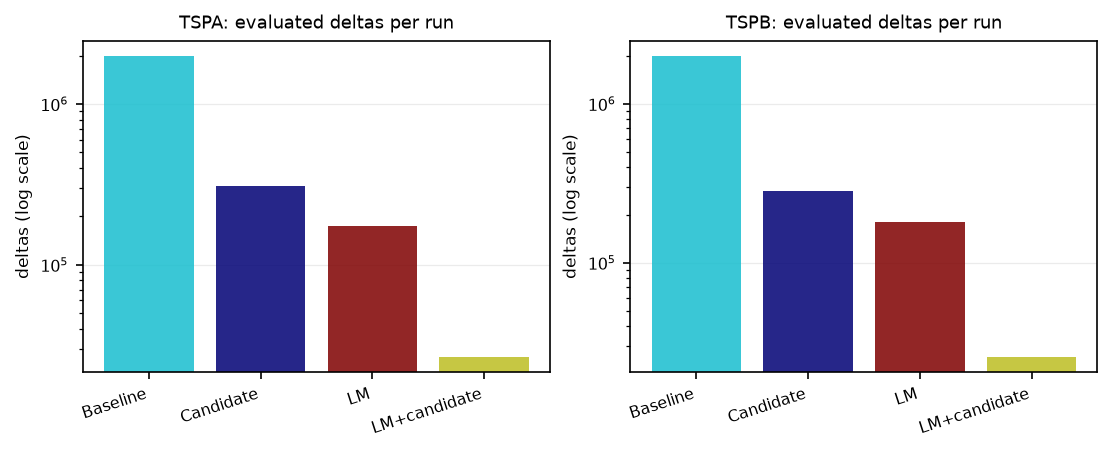

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 2.9), layout="constrained")
group = [BASELINE, CANDIDATE, LM_METHOD, LM_CAND]
labels = ["Baseline", "Candidate", "LM", "LM+candidate"]
for ax, name in zip(axes, INSTANCES):
    evaluated = [run_mean(name, m, "evaluated") for m in group]
    ax.bar(range(len(group)), evaluated, color=[COLORS[m] for m in group], alpha=0.85)
    ax.set_yscale("log")
    ax.set_xticks(range(len(group)))
    ax.set_xticklabels(labels, rotation=18, ha="right")
    ax.set_title(f"{name}: evaluated deltas per run")
    ax.set_ylabel("deltas (log scale)")
    ax.grid(axis="y", alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
fig.savefig(FIG / "evaluated.png", bbox_inches="tight")
plt.show()

### 12.6 Distribution of results

The box plots compare the four methods over the 200 runs. They show
the spread of objective values, not only the average.

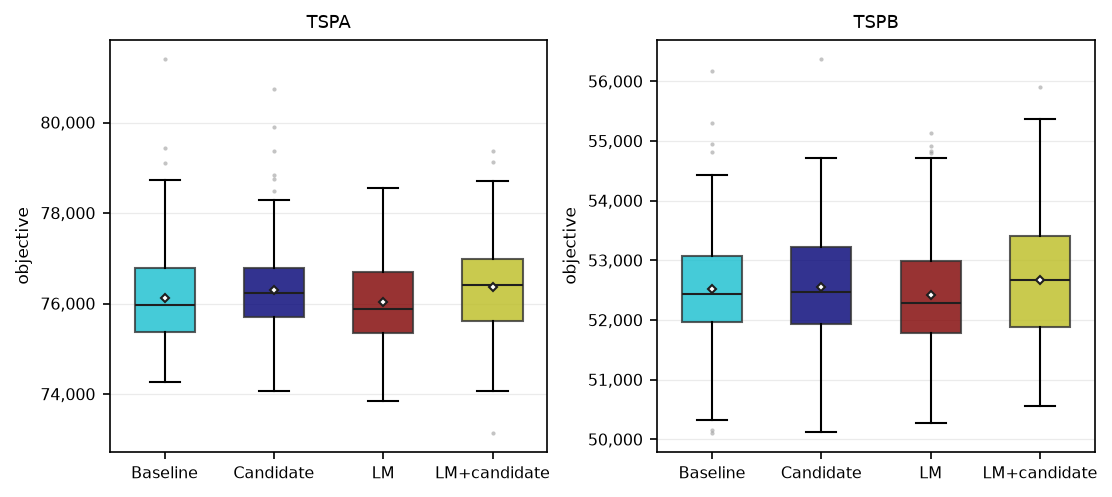

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 3.2), layout="constrained")
group = [BASELINE, CANDIDATE, LM_METHOD, LM_CAND]
for ax, name in zip(axes, INSTANCES):
    data = [runs.loc[(runs.instance == name) & (runs.method == m),
                     "objective"].to_numpy() for m in group]
    bp = ax.boxplot(
        data, tick_labels=[FIGURE_LABEL[m] for m in group], widths=0.55,
        patch_artist=True, showmeans=True,
        medianprops=dict(color="#1f1f1f", lw=1.0),
        meanprops=dict(marker="D", markerfacecolor="white",
                       markeredgecolor="#1f1f1f", markersize=3.0),
        flierprops=dict(marker="o", markersize=2.0, markerfacecolor="#8a8a8a",
                        markeredgecolor="none", alpha=0.5),
    )
    for patch, m in zip(bp["boxes"], group):
        patch.set_facecolor(COLORS[m])
        patch.set_alpha(0.8)
        patch.set_edgecolor("#333333")
    ax.set_title(name)
    ax.set_ylabel("objective")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(axis="y", alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
fig.savefig(FIG / "distributions.png", bbox_inches="tight")
plt.show()

## 13. Best solutions

Each panel shows the best tour found by one of the four methods. Grey dots are
nodes that were not selected. Selected nodes are drawn with a colour and a
radius that both encode the node cost: dark purple and small means cheap,
yellow and large means expensive. Thin arrows show the direction of travel
along the tour.

In [12]:
CMAP = plt.get_cmap("viridis")

def load_tour(name, method):
    row = tours[(tours.instance == name) & (tours.method == method)].iloc[0]
    return np.array([int(v) for v in str(row["tour"]).split()]), row

def draw(ax, name, method, norm, short=True):
    df = COORDS[name]
    tour, row = load_tour(name, method)
    sel = np.zeros(len(df), dtype=bool)
    sel[tour] = True
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    cost = df.cost.to_numpy()

    ax.scatter(x[~sel], y[~sel], s=5, c="#d4d4d4", linewidths=0, zorder=1)
    for i in range(len(tour)):
        a, b = tour[i], tour[(i + 1) % len(tour)]
        ax.annotate("", xy=(x[b], y[b]), xytext=(x[a], y[a]),
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=0.42,
                                    shrinkA=2.0, shrinkB=3.0, mutation_scale=5,
                                    alpha=0.75),
                    zorder=2)
    t = (cost[tour] - norm.vmin) / max(1e-9, norm.vmax - norm.vmin)
    ax.scatter(x[tour], y[tour], s=7 + 42 * t, c=cost[tour], cmap=CMAP,
               norm=norm, edgecolors="#1b1b1b", linewidths=0.35, zorder=3)

    label = FIGURE_LABEL.get(method, SHORT[method]) if short else LABELS[method]
    ax.set_title(f"{label}\nobjective {nf(row['objective'])}",
                 fontsize=7.0 if short else 8.2, pad=3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#dcdcdc")

def best_figure(name):
    norm = mpl.colors.Normalize(*COST_RANGE[name])
    group = [BASELINE, CANDIDATE, LM_METHOD, LM_CAND]
    ncol = 2
    nrow = (len(group) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(7.3, 2.15 * nrow),
                             layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, method in zip(axes, group):
        draw(ax, name, method, norm, short=True)
    for ax in axes[len(group):]:
        ax.axis("off")
    fig.suptitle(f"{name}: best solution for each method", fontsize=11)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=list(axes), fraction=0.022, pad=0.015)
    cb.set_label("node cost", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    fig.savefig(FIG / f"best_{name}.png", bbox_inches="tight")
    plt.show()

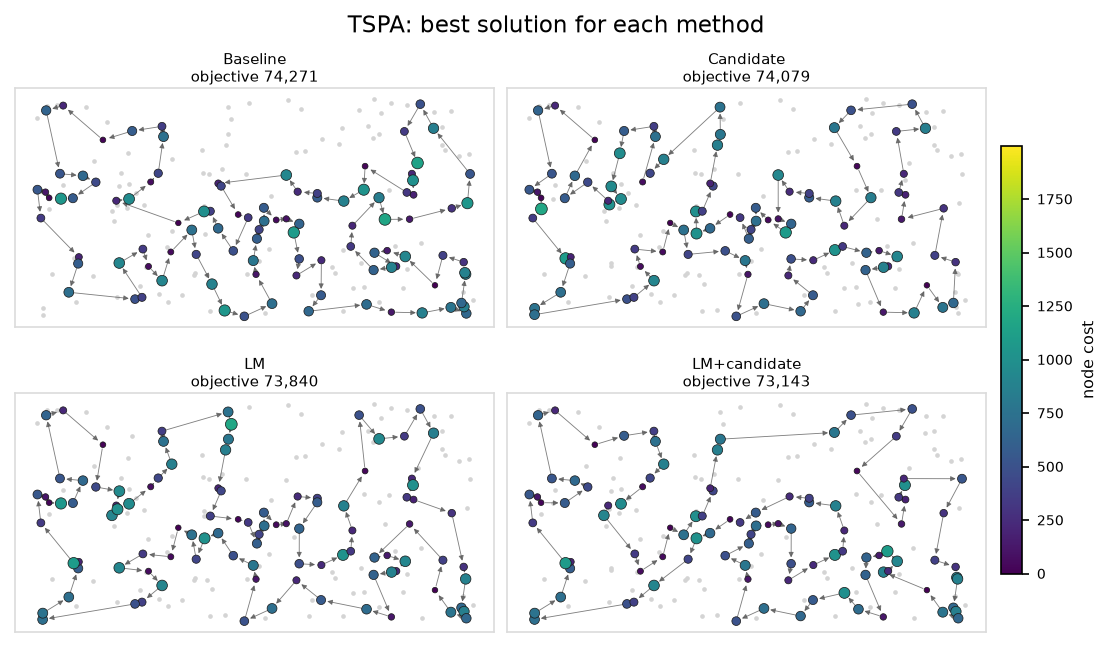

In [13]:
best_figure("TSPA")

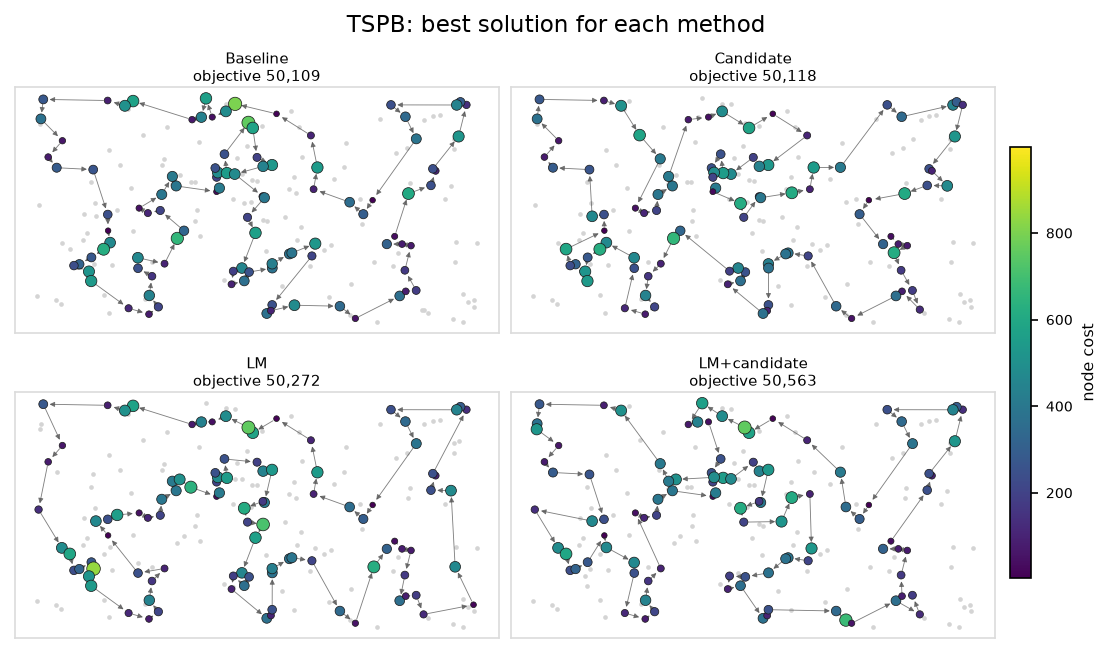

In [14]:
best_figure("TSPB")

## 14. Best tours as node lists

All indices are 0-based. Each list is the cycle order; the closing edge goes
from the last node back to the first one. Every tour visits exactly `k`
distinct nodes. The complete data is in `best_tours.csv`.

In [15]:
for name in INSTANCES:
    print(name)
    for method in [BASELINE, CANDIDATE, LM_METHOD, LM_CAND]:
        _, row = load_tour(name, method)
        idx = str(row["tour"]).split()
        print(f"\n{TABLE_LABEL[method]} — objective {nf(row['objective'])} "
              f"(distance {nf(row['distance'])}, costs {nf(row['costs'])}), "
              f"first node {int(row['first_node'])}:")
        for i in range(0, len(idx), 16):
            print("  " + " ".join(idx[i:i + 16]))
    print()

TSPA

Baseline: S/edge/rand — objective 74,271 (distance 22,246, costs 52,025), first node 157:
  157 91 80 48 31 60 108 152 49 11 63 149 116 168 97 127
  69 171 2 161 30 187 189 141 28 87 98 25 114 181 135 73
  140 53 179 52 177 36 131 99 84 58 134 158 192 182 57 64
  88 78 193 153 170 146 159 130 107 113 106 150 89 42 151 176
  174 85 81 93 47 37 147 101 29 178 59 1 169 50 3 164
  142 8 54 9 33 143 51 16 67 144 45 185 35 156 180 123
  90 132 76 71

Candidate moves — objective 74,079 (distance 22,666, costs 51,413), first node 177:
  177 52 179 53 140 144 67 185 102 156 35 16 51 139 112 115
  4 76 132 71 157 91 38 100 90 83 123 152 49 108 80 48
  31 60 116 149 63 119 168 95 97 127 69 129 104 171 2 189
  187 30 141 180 28 87 45 73 135 114 181 192 158 58 84 134
  72 176 150 106 113 89 42 151 57 64 107 88 153 159 130 47
  93 50 3 1 178 101 29 136 186 164 85 174 8 54 9 33
  143 36 131 99

LM — objective 73,840 (distance 22,203, costs 51,637), first node 9:
  9 54 131 84 134 72 176 174 8 1

## 15. Conclusions

- Full steepest search scans every move in every iteration. The LM remembers
  improving moves and their deltas and reuses them; a saved delta stays exact
  while the removed edges of the move still exist.
- The LM evaluates about eleven times fewer deltas and runs about six times
  faster than full steepest search, with slightly better average objective.
- Candidate moves make every scan smaller. Combined with the LM they give the
  fastest method: about 1.37 ms per run on TSPA and 1.40 ms on TSPB, about 8.6–8.7 times
  faster than full steepest search, with an average objective about 0.3% higher.
